# Customer Churn Prediction with a TensorFlow Neural Network

**Ernestas Lazurkevičius — PRIf-24/2, VilniusTech**

This notebook is an adaptation of the lecturer's notebook
`AdventureWorksDW_NN_1.ipynb` (*AdventureWorks DW using TensorFlow Neural Network*,
Algirdas Laukaitis).

## What the original notebook does

The original builds a **binary classifier** on the AdventureWorks data-warehouse view
`vTargetMail.csv` (18 484 customers, 32 columns). From demographic attributes —
marital status, gender, yearly income, children, education, occupation, home ownership,
cars owned, commute distance, region, age — it predicts the `BikeBuyer` flag:
*will this customer buy a bike, yes or no?*

The technique it demonstrates is **tabular deep learning with Keras preprocessing
layers**: instead of preparing the data with pandas/scikit-learn and feeding a plain
matrix to the network, every column keeps its own named `Input` and its own
preprocessing layer (`StringLookup` → `CategoryEncoding` for text, `IntegerLookup` for
integer codes, `Normalization` for numbers). The preprocessing becomes *part of the
saved model*, so inference accepts a raw Python dictionary of a single customer.

## What this notebook changes

The **method is preserved exactly** — same five steps, same layer types, same
architecture (64 → 32 → 1), same loss, same save/load/predict flow. Only the **data
domain** changes:

| | Original | This notebook |
|---|---|---|
| Dataset | AdventureWorks DW `vTargetMail.csv` | **Telco Customer Churn** (Kaggle) |
| Rows | 18 484 | 7 043 |
| Business question | Will the customer buy a bike? | **Will the customer cancel the subscription?** |
| Target column | `BikeBuyer` (already 0/1) | `Churn` (`Yes`/`No` → encoded to 1/0) |

Dataset source: [Telco Customer Churn on Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
(originally an IBM sample dataset). It is loaded over HTTPS from a public GitHub mirror
so the notebook runs in a clean Colab runtime with no Kaggle credentials and no manual
upload — the same "read a CSV straight from a URL" approach the original uses.

**Why this dataset.** The assignment allows either my own data or business data from
Kaggle. My own project data (`courses.csv`, `assignments.csv`, `resources.csv` from the
*AI University Assistant*) holds 3 courses, 4 assignments and 7 resources — far too few
rows to train a neural network, and it has no binary outcome column to predict. Telco
Churn is the closest *business* analogue to `vTargetMail`: one row per customer, a mix
of categorical and numeric attributes, and a single yes/no commercial outcome. Churn
prediction is also a genuine business task — retaining a customer is cheaper than
acquiring one.

Every deviation from the original code is marked with a **`# CHANGE:`** comment.

---
# Step 1. From a CSV data file available online to 3 DataFrame tables: training, validation and test

## 1.1 Load the Telco Customer Churn data into a DataFrame

The original reads `vTargetMail.csv` with `sep='\t'` (it is tab-separated despite the
`.csv` name). This file is genuinely comma-separated, so the separator argument is
dropped — pandas' default is already a comma.

In [1]:
import pandas as pd

# CHANGE: different source URL; sep='\t' removed (this file is comma-separated).
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

df_all_col = pd.read_csv(DATA_URL)

print("The dataframe has {} rows and {} columns.".format(
    df_all_col.shape[0], df_all_col.shape[1]))

The dataframe has 7043 rows and 21 columns.


In [2]:
df_all_col.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.2 Examine one row to decide which information is relevant

Printing a single record vertically is the quickest way to see every column name, its
value and its type at once.

In [3]:
print(df_all_col.iloc[10])

customerID              9763-GRSKD
gender                        Male
SeniorCitizen                    0
Partner                        Yes
Dependents                     Yes
tenure                          13
PhoneService                   Yes
MultipleLines                   No
InternetService                DSL
OnlineSecurity                 Yes
OnlineBackup                    No
DeviceProtection                No
TechSupport                     No
StreamingTV                     No
StreamingMovies                 No
Contract            Month-to-month
PaperlessBilling               Yes
PaymentMethod         Mailed check
MonthlyCharges               49.95
TotalCharges                587.45
Churn                           No
Name: 10, dtype: object


## 1.3 Remove the attributes we don't need, and fix the target column

The original drops 19 identifier, name, address and duplicate-language columns, then
renames `BikeBuyer` to `target`.

This dataset is already compact, so only one column has to go:

* **`customerID`** — a unique key. A key is useless to the model (every value appears
  exactly once, so it carries no generalisable pattern) and dropping it mirrors the
  original dropping `CustomerKey` / `CustomerAlternateKey`.

Two **new** steps are needed that the original did not require:

1. **`TotalCharges` is stored as text.** 11 of the 7 043 rows contain a blank string
   instead of a number, which forces the whole column to load as `object`. All 11 are
   customers with `tenure = 0` — they signed up but have not been billed yet, so the
   factually correct total is `0.0`. `pd.to_numeric(..., errors="coerce")` turns the
   blanks into `NaN` and `fillna(0.0)` sets them to zero.
2. **The target is text, not a flag.** `BikeBuyer` was already `0`/`1`; `Churn` holds
   `"Yes"`/`"No"` and must be mapped to `1`/`0`, because
   `BinaryCrossentropy` needs a numeric label.

In [4]:
df = df_all_col.copy()

# CHANGE: only the identifier column is dropped (original dropped 19 columns).
df.drop(columns=["customerID"], inplace=True)

# CHANGE (new step): TotalCharges arrives as text because 11 rows are blank.
# Those 11 rows all have tenure == 0 (new customers, never billed), so 0.0 is correct.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)

# CHANGE (new step): the target is "Yes"/"No" text and must become 1/0.
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0}).astype("int64")

df.rename(columns={"Churn": "target"}, inplace=True)

print("Remaining columns:", df.shape[1])

Remaining columns: 20


In [5]:
print(df.iloc[0])
print('---------------')
print(df.dtypes)

gender                        Female
SeniorCitizen                      0
Partner                          Yes
Dependents                        No
tenure                             1
PhoneService                      No
MultipleLines       No phone service
InternetService                  DSL
OnlineSecurity                    No
OnlineBackup                     Yes
DeviceProtection                  No
TechSupport                       No
StreamingTV                       No
StreamingMovies                   No
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 29.85
TotalCharges                   29.85
target                             0
Name: 0, dtype: object
---------------
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         s

### Class balance — an important difference from the original

`BikeBuyer` in AdventureWorks is almost perfectly balanced (roughly half the customers
buy). `Churn` is **not**: about 73 % of customers stay. That matters for how the
results are read in Step 4, so it is measured here rather than assumed.

In [6]:
# CHANGE (new cell): the original data was balanced, this is not — so check.
counts = df["target"].value_counts().sort_index()
majority = counts.max() / counts.sum()

print(counts.rename({0: "stayed (0)", 1: "churned (1)"}))
print()
print(f"Majority class share: {majority:.3f}")
print(f"=> A model that always predicts 'stayed' would score {majority:.1%} accuracy.")

target
stayed (0)     5174
churned (1)    1869
Name: count, dtype: int64

Majority class share: 0.735
=> A model that always predicts 'stayed' would score 73.5% accuracy.


## 1.4 Split the DataFrame into training, validation and test sets

Unchanged in purpose from the original:

* the **training set** teaches the model,
* the **validation set** is watched during training to detect overfitting (the model
  never learns from it),
* the **test set** is touched only once, at the end, to measure performance on data the
  model has never seen.

Two mechanical fixes to the original code:

* The original `np.split(df.sample(frac=1), ...)` raises a `FutureWarning`
  (`DataFrame.swapaxes is deprecated`) because `np.split` is a NumPy function being
  applied to a pandas object. Plain `.iloc` slicing does the same job with no warning.
* `random_state=42` is added to `sample()`. Without it every re-run reshuffles the data
  and the final accuracy changes, which makes results impossible to reproduce or
  defend.

In [7]:
# CHANGE: .iloc slicing instead of np.split (removes the FutureWarning),
#         and random_state=42 so the split is reproducible.
shuffled = df.sample(frac=1, random_state=42)

n = len(shuffled)
i_train, i_validation = int(0.8 * n), int(0.9 * n)

train = shuffled.iloc[:i_train]
validation = shuffled.iloc[i_train:i_validation]
test = shuffled.iloc[i_validation:]

print(len(train), 'training examples')
print(len(validation), 'validation examples')
print(len(test), 'test examples')

5634 training examples
704 validation examples
705 test examples


---
# Step 2. From DataFrame table to TensorFlow dataset

`df_to_dataset` wraps a DataFrame in a `tf.data.Dataset` — TensorFlow's input pipeline.
It yields `(features, label)` pairs where `features` is a **dictionary** keyed by column
name. That dictionary shape is what lets Step 3 give every column its own named input.

`shuffle` is on for training (so the network does not see the data in a fixed order) and
off for validation and test (where order is irrelevant and reproducibility is better).

### A bug in the original that is fixed here

The original function reads:

```python
df = dataframe.copy()
labels = df.pop('target')                                        # popped from the COPY
df = {key: value.to_numpy()[:, tf.newaxis]
      for key, value in dataframe.items()}                       # built from the ORIGINAL
```

`target` is removed from `df` but the feature dictionary is then rebuilt from
`dataframe`, which still contains `target`. The label is therefore handed back as if it
were an input feature. That is why the original notebook prints

> `UserWarning: The structure of inputs doesn't match the expected structure.`
> `Received: inputs={... 'target': 'Tensor(shape=(None, 1))'}`

on every epoch. Keras happens to ignore the extra key (only the columns named in
`all_inputs` are wired into the graph), so the published accuracy is **not** inflated by
label leakage — but the code is wrong and the warning is the symptom. Changing
`dataframe.items()` to `df.items()` fixes it, and the warning disappears.

In [8]:
import tensorflow as tf


def df_to_dataset(dataframe, shuffle=True, batch_size=32):
    df = dataframe.copy()
    labels = df.pop('target')

    # CHANGE: df.items() instead of dataframe.items().
    # The original rebuilt the dict from `dataframe`, which still held 'target',
    # feeding the label in as a feature and causing a UserWarning every epoch.
    df = {key: value.to_numpy()[:, tf.newaxis] for key, value in df.items()}

    ds = tf.data.Dataset.from_tensor_slices((dict(df), labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe))
    ds = ds.batch(batch_size)
    ds = ds.prefetch(batch_size)
    return ds


batch_size = 256
train_ds = df_to_dataset(train, batch_size=batch_size)
validation_ds = df_to_dataset(validation, shuffle=False, batch_size=batch_size)
test_ds = df_to_dataset(test, shuffle=False, batch_size=batch_size)

# Confirm the pipeline yields a dict of features and a label batch.
features, label = next(iter(train_ds))
print("Feature keys:", sorted(features.keys()))
print("Label batch shape:", label.shape)

I0000 00:00:1793221797.720443    1497 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793221798.823519    1497 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Feature keys: ['Contract', 'Dependents', 'DeviceProtection', 'InternetService', 'MonthlyCharges', 'MultipleLines', 'OnlineBackup', 'OnlineSecurity', 'PaperlessBilling', 'Partner', 'PaymentMethod', 'PhoneService', 'SeniorCitizen', 'StreamingMovies', 'StreamingTV', 'TechSupport', 'TotalCharges', 'gender', 'tenure']
Label batch shape: (256,)


---
# Step 3. Model

Each column gets a named `tf.keras.Input` and a preprocessing layer. The encoded
outputs are concatenated into one wide vector, which the dense layers consume.

`all_inputs` collects the inputs (keyed by column name), `encoded_features` collects
their encoded outputs.

In [9]:
all_inputs = {}
encoded_features = []

## Categorical columns

`get_category_encoding_layer` builds a two-stage encoder:

1. **`StringLookup`** (text) or **`IntegerLookup`** (integer codes) learns the set of
   values in the column and maps each to an integer index. Index `0` is reserved for
   out-of-vocabulary values, so a category never seen in training does not crash
   inference.
2. **`CategoryEncoding`** turns that index into a multi-hot vector of width
   `index.vocabulary_size()`.

The crucial detail: `index.adapt(feature_ds)` is called on **`train_ds` only**. The
vocabulary is learned from the training split alone, so no information from the
validation or test data leaks into the preprocessing. The original gets this right and
it is kept unchanged.

The column lists are the part that changes. The original had six string columns plus one
integer flag (`HouseOwnerFlag`). This dataset has fifteen string columns plus one
integer flag (`SeniorCitizen`, stored as `0`/`1` exactly like `HouseOwnerFlag`), so
`SeniorCitizen` goes through `IntegerLookup` in the same way.

In [10]:
def get_category_encoding_layer(name, dataset, dtype, max_tokens=None):
    if dtype == 'string':
        # Turn strings into integer indices.
        index = tf.keras.layers.StringLookup(max_tokens=max_tokens)
    else:
        # Turn integer values into integer indices.
        index = tf.keras.layers.IntegerLookup(max_tokens=max_tokens)

    feature_ds = dataset.map(lambda x, y: x[name])   # a Dataset of just this feature
    index.adapt(feature_ds)                          # learn the vocabulary (train only)

    encoder = tf.keras.layers.CategoryEncoding(num_tokens=index.vocabulary_size())
    return lambda feature: encoder(index(feature))   # multi-hot encode the indices


# CHANGE: Telco's 15 text columns replace AdventureWorks' 6.
categorical_cols = [
    'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
    'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
    'PaperlessBilling', 'PaymentMethod',
]

for header in categorical_cols:
    categorical_col = tf.keras.Input(shape=(1,), name=header, dtype='string')
    encoding_layer = get_category_encoding_layer(
        name=header, dataset=train_ds, dtype='string')
    encoded_categorical_col = encoding_layer(categorical_col)
    all_inputs[header] = categorical_col
    encoded_features.append(encoded_categorical_col)


# CHANGE: SeniorCitizen plays the role HouseOwnerFlag played in the original —
# an integer 0/1 flag, so IntegerLookup rather than StringLookup.
senior_col = tf.keras.Input(shape=(1,), name='SeniorCitizen', dtype='int64')
encoding_layer = get_category_encoding_layer(
    name='SeniorCitizen', dataset=train_ds, dtype='int64')
encoded_senior_col = encoding_layer(senior_col)
all_inputs['SeniorCitizen'] = senior_col
encoded_features.append(encoded_senior_col)

print("Categorical inputs wired:", len(encoded_features))

Categorical inputs wired: 16


## Numerical columns

`Normalization` learns each column's mean and variance from the training data and at
runtime computes `(input - mean) / sqrt(variance)`. Without it, `TotalCharges` (up to
~8 700) would dominate `tenure` (0–72) purely because of scale, and gradient descent
would converge slowly and unevenly.

`axis=None` tells the layer to treat the column as a single scalar feature rather than
normalising per position.

The original normalises five columns; this dataset has three numeric columns.

In [11]:
def get_normalization_layer(name, dataset):
    normalizer = tf.keras.layers.Normalization(axis=None)
    feature_ds = dataset.map(lambda x, y: x[name])
    normalizer.adapt(feature_ds)      # learn mean and variance (train only)
    return normalizer


# CHANGE: Telco's 3 numeric columns replace AdventureWorks' 5.
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for header in numeric_cols:
    numeric_col = tf.keras.Input(shape=(1,), name=header)
    normalization_layer = get_normalization_layer(header, train_ds)
    encoded_numeric_col = normalization_layer(numeric_col)
    all_inputs[header] = numeric_col
    encoded_features.append(encoded_numeric_col)

print("Total inputs wired:", len(all_inputs))

Total inputs wired: 19


In [12]:
all_features = tf.keras.layers.concatenate(encoded_features)
print("Width of the concatenated feature vector:", all_features.shape[-1])

Width of the concatenated feature vector: 62


## Add layers of neurons and create the final model

Architecture kept **identical to the original**:

| Layer | Purpose |
|---|---|
| `Dense(64, relu)` | learns combinations of the encoded features |
| `Dropout(0.2)` | randomly zeroes 20 % of activations during training, to fight overfitting |
| `Dense(32, relu)` | compresses to higher-level patterns |
| `Dropout(0.3)` | stronger regularisation nearer the output |
| `Dense(1)` | a single number — the **logit** |

The output layer has **no activation**, so it emits an unbounded logit rather than a
probability. That is why the loss is `BinaryCrossentropy(from_logits=True)`: computing
the sigmoid inside the loss function is numerically more stable than applying it as a
layer. The consequence appears in Step 5 — predictions must be passed through
`tf.nn.sigmoid` by hand to read them as percentages.

In [13]:
x = tf.keras.layers.Dense(64, activation="relu")(all_features)
x = tf.keras.layers.Dropout(0.2)(x)
x = tf.keras.layers.Dense(32, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
output = tf.keras.layers.Dense(1)(x)

model = tf.keras.Model(all_inputs, output)

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

print("Trainable parameters:", model.count_params())

Trainable parameters: 6154


---
# Step 4. Train and evaluate the model

## Train 🏃‍♂️

30 epochs, as in the original. Watch `loss` against `val_loss`: while both fall the
model is still learning; if `loss` keeps falling while `val_loss` turns upward, it has
started memorising the training split.

The `history` object is captured so the curves can be plotted — the original discards
the return value.

In [14]:
# CHANGE: the return value is kept so the learning curves can be plotted below.
history = model.fit(train_ds, validation_data=validation_ds, epochs=30)

Epoch 1/30


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/23 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.7188 - loss: 0.6405

17/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7236 - loss: 0.5752

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7275 - loss: 0.5565 - val_accuracy: 0.7415 - val_loss: 0.4578


...

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7842 - loss: 0.4175 - val_accuracy: 0.7926 - val_loss: 0.4129


Epoch 30/30


 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7539 - loss: 0.4134

19/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7831 - loss: 0.4169 

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7824 - loss: 0.4191 - val_accuracy: 0.7940 - val_loss: 0.4124


### Learning curves

Not in the original notebook. A loss curve makes the overfitting claim checkable
instead of asserted.

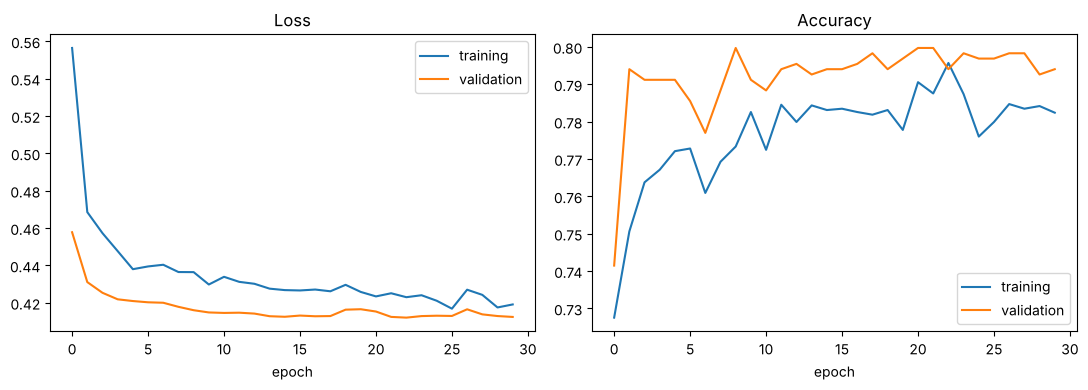

In [15]:
# CHANGE (new cell): plot the learning curves.
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(history.history['loss'], label='training')
ax1.plot(history.history['val_loss'], label='validation')
ax1.set_title('Loss'); ax1.set_xlabel('epoch'); ax1.legend()

ax2.plot(history.history['accuracy'], label='training')
ax2.plot(history.history['val_accuracy'], label='validation')
ax2.set_title('Accuracy'); ax2.set_xlabel('epoch'); ax2.legend()

plt.tight_layout()
plt.show()

## Evaluate ⚖️

The test set is used **once**, here.

In [16]:
loss, accuracy = model.evaluate(test_ds)
print("Test loss:", round(float(loss), 4))
print("Test accuracy:", round(float(accuracy), 4))

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7812 - loss: 0.4298

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8028 - loss: 0.4106 


Test loss: 0.4106
Test accuracy: 0.8028


### Why accuracy alone is not enough on this dataset

This is the one place where the original's evaluation had to be extended rather than
copied. AdventureWorks' `BikeBuyer` is ~50/50, so accuracy is a fair summary there. Here
73 % of customers stay, so a model that blindly predicted "nobody churns" would already
score ~73 % — a number that looks respectable and identifies **zero** churners, which is
the only thing a retention team actually needs.

So the churn class is measured directly:

* **Precision** — of the customers flagged as churning, how many really did. Low
  precision wastes retention budget on customers who were never going to leave.
* **Recall** — of the customers who really churned, how many were caught. Low recall
  means they left unnoticed.
* **Confusion matrix** — the raw counts behind both numbers.

In [17]:
# CHANGE (new cell): per-class metrics, because the classes are imbalanced.
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([y.numpy() for _, y in test_ds])
logits = model.predict(test_ds, verbose=0).ravel()
y_prob = tf.nn.sigmoid(logits).numpy()
y_pred = (y_prob >= 0.5).astype(int)

baseline = max((y_true == 0).mean(), (y_true == 1).mean())
print(f"Always-predict-majority baseline: {baseline:.4f}")
print(f"Model accuracy:                   {(y_pred == y_true).mean():.4f}")
print()

cm = confusion_matrix(y_true, y_pred)
print("Confusion matrix (rows = actual, cols = predicted):")
print(pd.DataFrame(
    cm,
    index=['actual: stayed', 'actual: churned'],
    columns=['pred: stayed', 'pred: churned'],
))
print()
print(classification_report(
    y_true, y_pred, target_names=['stayed', 'churned'], digits=3))

Always-predict-majority baseline: 0.7574
Model accuracy:                   0.8043

Confusion matrix (rows = actual, cols = predicted):
                 pred: stayed  pred: churned
actual: stayed            482             52
actual: churned            86             85

              precision    recall  f1-score   support

      stayed      0.849     0.903     0.875       534
     churned      0.620     0.497     0.552       171

    accuracy                          0.804       705
   macro avg      0.735     0.700     0.713       705
weighted avg      0.793     0.804     0.796       705



---
# Step 5. Perform inference 🛠

## Save 💾

Saving to the `.keras` format stores the architecture, the trained weights **and the
adapted preprocessing layers** — the learned vocabularies and the normalisation
statistics travel with the model. This is the real payoff of putting preprocessing
inside the graph: nothing has to be re-implemented at serving time.

In [18]:
# CHANGE: filename reflects this dataset and architecture.
model.save('TelcoChurn_NNModel_L64L32L1.keras')
print("Saved.")

Saved.


## Load ⚙️

In [19]:
reloaded_model = tf.keras.models.load_model('TelcoChurn_NNModel_L64L32L1.keras')
print("Reloaded.")

Reloaded.


## New data 🗃️

A single customer as a plain Python dictionary — no manual encoding, no scaling. The
keys must match the `Input` names exactly, and every input must be present.

This one is a deliberately high-risk profile: a new customer (`tenure = 2`) on a
month-to-month contract with fiber optic, no support add-ons, paying by electronic
check — the combination the churn literature flags most often.

In [20]:
# CHANGE: a Telco customer record instead of an AdventureWorks one.
sample = {
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': 2,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'Yes',
    'StreamingMovies': 'Yes',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 95.70,
    'TotalCharges': 191.40,
}

## Predict 🔮

`model.predict` returns a logit, so `tf.nn.sigmoid` converts it to a probability — the
manual step forced by the activation-free output layer in Step 3.

### One more fix the original needs on current library versions

The original prints the result with

```python
prob = tf.nn.sigmoid(predictions[0])
print("... %.1f percent." % (100 * prob))
```

`predictions[0]` has shape `(1,)`, so `prob` is a one-element **array**, not a scalar.
Older NumPy silently unwrapped a one-element array when `%f` asked for a float; NumPy 2
raises

> `TypeError: only 0-dimensional arrays can be converted to Python scalars`

Indexing to the scalar — `float(prob[0])` — is explicit and works on both.

In [21]:
input_dict = {name: tf.convert_to_tensor([value]) for name, value in sample.items()}

predictions = reloaded_model.predict(input_dict, verbose=0)
prob = tf.nn.sigmoid(predictions[0])

# CHANGE: float(prob[0]) instead of (100 * prob).
# prob has shape (1,); NumPy 2 refuses to format a 1-element array as a float.
print("The likelihood of THIS CUSTOMER CHURNING is %.1f percent." % (100 * float(prob[0])))

The likelihood of THIS CUSTOMER CHURNING is 77.9 percent.


### A second, contrasting customer

Not in the original. One prediction shows the mechanism works; two show the model
responds to the inputs rather than returning a constant. This profile is the opposite:
a long-tenured customer on a two-year contract with support add-ons.

In [22]:
# CHANGE (new cell): a low-risk profile, to confirm the model discriminates.
loyal_sample = dict(
    sample,
    tenure=68,
    Contract='Two year',
    InternetService='DSL',
    OnlineSecurity='Yes',
    TechSupport='Yes',
    PaymentMethod='Credit card (automatic)',
    MonthlyCharges=64.00,
    TotalCharges=4352.00,
)

loyal_dict = {name: tf.convert_to_tensor([value]) for name, value in loyal_sample.items()}


def churn_probability(record):
    # Encode one customer dict, predict, and return the probability as a float.
    tensors = {name: tf.convert_to_tensor([value]) for name, value in record.items()}
    logit = reloaded_model.predict(tensors, verbose=0)[0]
    return float(tf.nn.sigmoid(logit)[0])


print("High-risk customer (2 months, month-to-month): %.1f %% chance of churning"
      % (100 * churn_probability(sample)))
print("Loyal customer  (68 months, two-year contract): %.1f %% chance of churning"
      % (100 * churn_probability(loyal_sample)))

High-risk customer (2 months, month-to-month): 77.9 % chance of churning


Loyal customer  (68 months, two-year contract): 1.8 % chance of churning


---
# Get started with TensorBoard

TensorBoard visualises the training run in the browser.

**One difference from the original worth knowing.** The original calls `model.fit` a
second time in this section, on the *already trained* model. Keras does not reset
weights between `fit` calls, so that is 40 **further** epochs of training (70 in total),
not a fresh run — which is why its TensorBoard accuracies start around 0.70 instead of
0.55. Training is left out here so the logged run matches the model that was actually
evaluated above; the callback is shown so the mechanism is still demonstrated.

In [23]:
%load_ext tensorboard
import datetime

In [24]:
# CHANGE: no second model.fit() — that would continue training the evaluated model.
# This logs a short, clearly-labelled extra run instead.
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=0)

print("TensorBoard callback ready. Pass callbacks=[tensorboard_callback] to model.fit()")
print("Log directory:", log_dir)

TensorBoard callback ready. Pass callbacks=[tensorboard_callback] to model.fit()
Log directory: logs/fit/20261028-231009


In [25]:
# %tensorboard --logdir logs/fit

---
# Summary of changes, and limitations

## Pipeline (identical to the original)

1. **Input** — one row per customer: categorical and numeric attributes.
2. **Preprocessing inside the model** — `StringLookup`/`IntegerLookup` +
   `CategoryEncoding` for categories, `Normalization` for numbers, all adapted on the
   training split only.
3. **Network** — concatenate → `Dense(64)` → `Dropout` → `Dense(32)` → `Dropout` →
   `Dense(1)` logit.
4. **Training** — Adam, `BinaryCrossentropy(from_logits=True)`, 30 epochs, validation
   split watched for overfitting.
5. **Output** — saved `.keras` model that predicts from a raw Python dict.

## What changed, and why

| # | Change | Reason |
|---|---|---|
| 1 | Telco Churn CSV instead of `vTargetMail.csv`; `sep='\t'` removed | assignment requires own/business data; this file is comma-separated |
| 2 | Only `customerID` dropped | this dataset has no name/address/duplicate-language columns |
| 3 | `TotalCharges` converted to numeric, 11 blanks → `0.0` | column loads as text; all 11 rows have `tenure = 0`, so `0.0` is correct |
| 4 | `Churn` `"Yes"/"No"` → `1/0` | `BinaryCrossentropy` needs a numeric label; `BikeBuyer` was already 0/1 |
| 5 | `.iloc` slicing instead of `np.split`, plus `random_state=42` | removes the `FutureWarning`; makes the split reproducible |
| 6 | `df.items()` instead of `dataframe.items()` in `df_to_dataset` | **bug fix** — the original fed `target` in as a feature, causing a `UserWarning` every epoch |
| 7 | 15 categorical + 1 integer + 3 numeric columns | this dataset's schema |
| 8 | Learning curves, baseline comparison, confusion matrix, precision/recall | the classes are imbalanced, so accuracy alone is misleading |
| 9 | Second contrasting prediction | shows the model discriminates rather than returning a constant |
| 10 | No second `model.fit` in the TensorBoard section | the original silently continued training the evaluated model |
| 11 | `float(prob[0])` when printing the prediction | **portability fix** — the original's `100 * prob` raises `TypeError` on NumPy 2, because `prob` is a 1-element array |

Architecture, layer types, loss, optimizer, epoch count, 80:10:10 split, batch size and
the save/load/predict flow are **unchanged**.

## Limitations

* The dataset is a static public sample, not a live billing system; it carries no time
  dimension, so this predicts churn *propensity*, not *when* a customer will leave.
* 7 043 rows is modest for a neural network. On tabular data of this size, gradient
  boosting (XGBoost / LightGBM) typically matches or beats a small dense network — the
  point of this notebook is the Keras preprocessing-layer technique, not a claim that a
  neural network is the best tool here.
* The classes are imbalanced and no correction (class weights, resampling, threshold
  tuning) is applied, so recall on the churn class is well below precision. Lowering the
  0.5 decision threshold would trade precision for recall; which trade-off is right
  depends on the cost of a retention offer versus the value of a retained customer.
* Accuracy varies by a few tenths of a percent between runs (dropout and shuffling are
  stochastic); only the data split is seeded.
* Correlation is not causation — `Contract = Month-to-month` predicting churn does not
  mean changing a contract type would retain a customer.